# EDA Small Dataset - Geography & Distances
**Author:** Alexandre Silva

**Context:** Preliminary delivery focusing on geographical data extraction from the `data_small` dataset.
**Goals:**
1. Generate distance matrix and geographic map for the small dataset.
2. Calculate distance from the collection center to each stop.
3. Identify the nearest neighbor for each stop and group close locations.
4. Estimate minimum daily distance using Minimum Spanning Tree (MST).
5. Prepare heuristics (Max Distance and MST) for A* and Greedy algorithms.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import folium

# Define dataset path
DATA_PATH = os.path.join("docs", "data_small_30_31oct2026")

# Load necessary CSV files
distance_matrix_df = pd.read_csv(os.path.join(DATA_PATH, "distance_matrix.csv"))
locations_df = pd.read_csv(os.path.join(DATA_PATH, "locations.csv"))
collection_centers_df = pd.read_csv(os.path.join(DATA_PATH, "collection_centers.csv"))
order_items_df = pd.read_csv(os.path.join(DATA_PATH, "order_items.csv"))

print("Small dataset files loaded successfully!")
print(f"Total distance pairs: {len(distance_matrix_df)}")
print(f"Total locations: {len(locations_df)}")

Small dataset files loaded successfully!
Total distance pairs: 182
Total locations: 14


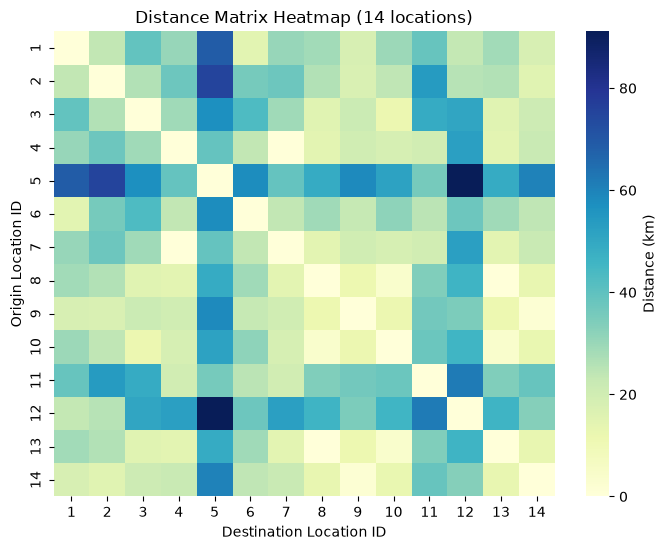

destination_location_id,1,2,3,4,5,6,7,8,9,10,11,12,13,14
origin_location_id,,,,,,,,,,,,,,
1,0.00,23.59,39.30,30.60,68.77,14.86,30.60,28.69,18.09,29.90,38.62,23.17,28.69,17.95
2,23.59,0.00,26.05,37.66,75.12,35.74,37.66,26.27,17.56,24.19,53.80,25.48,26.27,15.48
3,39.30,26.05,0.00,29.06,57.31,43.34,29.06,15.53,21.51,11.90,48.92,50.81,15.53,21.35
4,30.60,37.66,29.06,0.00,38.88,23.53,0.00,14.30,20.22,18.16,19.85,52.33,14.30,22.27
5,68.77,75.12,57.31,38.88,0.00,58.01,38.88,48.98,58.44,51.71,35.70,91.13,48.98,60.39


In [4]:
# --- Section 1: Distance Matrix and Heatmap ---

def generate_distance_matrix(distance_df):
    """
    Pivots the distance dataframe into a 2D matrix (Origin x Destination).
    """
    matrix_2d = distance_df.pivot(
        index='origin_location_id', 
        columns='destination_location_id', 
        values='distance_km'
    )
    matrix_2d = matrix_2d.fillna(0)
    return matrix_2d

def plot_heatmap(matrix_2d):
    """
    Plots a heatmap for the distance matrix.
    """
    num_nodes = len(matrix_2d)
    fig_size = min(num_nodes * 0.5, 20) 
    
    plt.figure(figsize=(fig_size, fig_size * 0.8))
    sns.heatmap(matrix_2d, cmap="YlGnBu", cbar_kws={'label': 'Distance (km)'})
    
    plt.title(f"Distance Matrix Heatmap ({num_nodes} locations)")
    plt.xlabel("Destination Location ID")
    plt.ylabel("Origin Location ID")
    plt.tight_layout()
    plt.show()

# Execution
dist_matrix_2d = generate_distance_matrix(distance_matrix_df)
plot_heatmap(dist_matrix_2d)

dist_matrix_2d.head()

In [5]:
# --- Section 2: Geographic Map ---

def create_geographic_map(loc_df):
    """
    Generates an interactive Folium map with all routing locations.
    The map is automatically centered based on the dataset coordinates.
    """
    # Dynamically calculate the center of the map
    mean_lat = loc_df['latitude'].mean()
    mean_lon = loc_df['longitude'].mean()
    
    # Initialize the map
    route_map = folium.Map(location=[mean_lat, mean_lon], zoom_start=11)
    
    # Add markers for each location
    for _, row in loc_df.iterrows():
        loc_id = row['location_id']
        lat = row['latitude']
        lon = row['longitude']
        
        # Add a basic marker
        folium.Marker(
            location=[lat, lon],
            popup=f"Location ID: {loc_id}",
            icon=folium.Icon(color="blue", icon="info-sign")
        ).add_to(route_map)
        
    return route_map

# Execution
map_small = create_geographic_map(locations_df)

# Display the map in the notebook
map_small

In [8]:
# --- Section 3: Proximity Analysis & Clustering ---

def get_furthest_stops(dist_df, base_id):
    """
    Filters the distance matrix for a specific origin (the base) 
    and sorts the destinations to find the furthest stops.
    """
    base_distances = dist_df[dist_df['origin_location_id'] == base_id].copy()
    return base_distances.sort_values(by='distance_km', ascending=False)

def get_nearest_neighbors(dist_df):
    """
    Identifies the single nearest neighbor for every routing stop.
    Excludes distance to itself (0 km).
    """
    valid_dists = dist_df[dist_df['distance_km'] > 0]
    nearest_idx = valid_dists.groupby('origin_location_id')['distance_km'].idxmin()
    return valid_dists.loc[nearest_idx]

def build_proximity_clusters(dist_df, radius_km=5.0):
    """
    Groups stops that are within a specific radius (km) of each other.
    Returns a dictionary mapping each origin to a list of close destinations.
    """
    close_stops = dist_df[(dist_df['distance_km'] > 0) & 
                          (dist_df['distance_km'] <= radius_km)]
    
    return close_stops.groupby('origin_location_id')['destination_location_id'].apply(list).to_dict()

# --- Execution ---

# Extract the base location ID from collection centers
base_node_id = collection_centers_df.iloc[0]['location_id'] if 'location_id' in collection_centers_df.columns else collection_centers_df.iloc[0].values[0]
print(f"Analyzing distances from Base Location ID: {base_node_id}\n")

# 1. Furthest stops from base
furthest_stops_df = get_furthest_stops(distance_matrix_df, base_node_id)
print("Top 5 furthest stops from base:")
display(furthest_stops_df[['origin_location_id', 'destination_location_id', 'distance_km', 'duration_min']].head(5))

# 2. Nearest neighbor for each stop
nearest_neighbors_df = get_nearest_neighbors(distance_matrix_df)
print("\nNearest neighbor for first 5 stops:")
display(nearest_neighbors_df[['origin_location_id', 'destination_location_id', 'distance_km', 'duration_min']].head(5))

# 3. Proximity clusters (e.g. within 5 km)
clusters = build_proximity_clusters(distance_matrix_df, radius_km=5.0)
print(f"\nStops within 5km of Base (ID {base_node_id}): {clusters.get(base_node_id, 'None')}")

Analyzing distances from Base Location ID: 1

Top 5 furthest stops from base:


,origin_location_id,destination_location_id,distance_km,duration_min
3,1,5,68.77,91.7
1,1,3,39.30,52.4
9,1,11,38.62,51.5
5,1,7,30.60,40.8
2,1,4,30.60,40.8



Nearest neighbor for first 5 stops:


,origin_location_id,destination_location_id,distance_km,duration_min
4,1,6,14.86,19.8
25,2,14,15.48,20.6
34,3,10,11.90,15.9
45,4,8,14.30,19.1
61,5,11,35.70,47.6



Stops within 5km of Base (ID 1): None


In [9]:
# --- Section 4: Daily Minimum Spanning Tree (MST) & Heuristics ---

class UnionFind:
    """
    Disjoint-set data structure (Union-Find) to support Kruskal's MST algorithm.
    """
    def __init__(self, elements):
        self.parent = {el: el for el in elements}

    def find(self, i):
        if self.parent[i] == i:
            return i
        self.parent[i] = self.find(self.parent[i])
        return self.parent[i]

    def union(self, i, j):
        root_i = self.find(i)
        root_j = self.find(j)
        if root_i != root_j:
            self.parent[root_i] = root_j
            return True
        return False

def compute_mst_distance(nodes, dist_df):
    """
    Calculates the Minimum Spanning Tree (MST) distance for a set of location nodes
    using Kruskal's algorithm.
    """
    if len(nodes) <= 1:
        return 0.0
    
    # Filter distance pairs that connect only the given set of nodes
    edges_df = dist_df[
        (dist_df['origin_location_id'].isin(nodes)) & 
        (dist_df['destination_location_id'].isin(nodes)) &
        (dist_df['distance_km'] > 0)
    ].sort_values(by='distance_km')
    
    uf = UnionFind(nodes)
    mst_weight = 0.0
    edges_count = 0
    
    for _, row in edges_df.iterrows():
        u = row['origin_location_id']
        v = row['destination_location_id']
        w = row['distance_km']
        
        if uf.union(u, v):
            mst_weight += w
            edges_count += 1
            if edges_count == len(nodes) - 1:
                break
                
    return round(mst_weight, 2)

# --- Heuristics for A* and Greedy Search ---

def heuristic_max_distance(current_node, remaining_nodes, dist_df):
    """
    Heuristic 1: Returns the distance from the current node 
    to the furthest unvisited node in remaining_nodes.
    """
    if not remaining_nodes:
        return 0.0
    
    sub_df = dist_df[
        (dist_df['origin_location_id'] == current_node) & 
        (dist_df['destination_location_id'].isin(remaining_nodes))
    ]
    if sub_df.empty:
        return 0.0
    
    return float(sub_df['distance_km'].max())

def heuristic_mst(current_node, remaining_nodes, dist_df):
    """
    Heuristic 2: Returns the distance to the nearest unvisited node 
    plus the MST weight of all remaining unvisited nodes.
    """
    if not remaining_nodes:
        return 0.0
    
    # Distance from current node to nearest remaining node
    sub_df = dist_df[
        (dist_df['origin_location_id'] == current_node) & 
        (dist_df['destination_location_id'].isin(remaining_nodes)) &
        (dist_df['distance_km'] > 0)
    ]
    
    min_dist_to_next = float(sub_df['distance_km'].min()) if not sub_df.empty else 0.0
    
    # MST weight of remaining nodes
    mst_weight = compute_mst_distance(remaining_nodes, dist_df)
    
    return min_dist_to_next + mst_weight

# --- Execution ---

# 1. Test MST on all dataset locations
all_locations = locations_df['location_id'].tolist()
total_mst = compute_mst_distance(all_locations, distance_matrix_df)
print(f"MST Total Minimum Distance (All {len(all_locations)} locations): {total_mst} km")

# 2. Test Heuristics from Base Node (ID 1) with remaining unvisited nodes [2, 3, 4, 5, 6]
sample_remaining = [2, 3, 4, 5, 6]
h_max = heuristic_max_distance(base_node_id, sample_remaining, distance_matrix_df)
h_mst = heuristic_mst(base_node_id, sample_remaining, distance_matrix_df)

print(f"\nHeuristic Evaluation from Node {base_node_id} with remaining stops {sample_remaining}:")
print(f" -> Heuristic 1 (Max Distance): {h_max} km")
print(f" -> Heuristic 2 (Nearest + MST): {h_mst} km")

MST Total Minimum Distance (All 14 locations): 188.93 km

Heuristic Evaluation from Node 1 with remaining stops [2, 3, 4, 5, 6]:
 -> Heuristic 1 (Max Distance): 68.77 km
 -> Heuristic 2 (Nearest + MST): 132.38 km
